# E2 — does NISAR improve the 2026 water-level models?

**Hypothesis test:** F5 (S1 + S2 + NISAR) vs F3 (S1 + S2), primary model = random forest.

| | |
|---|---|
| Unit | field × day (5 fields; Way 3 and Way 4 = mean of their gauges on days both have data, else the one gauge) |
| Features | same format as the 2021–2024 model: one column per variable per day for days t−14 … t−1 (`<sensor>_<var>_lag1..lag14`). **Window, fill, unit and variables are set in the config cell**; features are built in section 2 with `scripts/build_causal_features_2026.py` |
| Radar tracks | S1 orbits and NISAR tracks pooled into one series each; incidence angle (`inc_deg`) selectable in `VARIABLES` |
| Targets | binary (< 0 cm), 3-class (< −1 / −1…5 / > 5 cm), water level (cm) |
| CV | leave one field group out: {Way 3 + Way 4}, 4 East, South 0, S16 |
| Hold-out test | none (`HOLDOUT_FIELDS = []`); section 6 runs only if a field is listed there |
| Primary metrics | balanced accuracy (binary), macro-F1 (3-class), RMSE (regression) |
| Significance | exact permutation test + field-block bootstrap CI (section 7), currently OFF: `RUN_SIGNIFICANCE = False` |

Hyperparameters are fixed in the config cell (no tuning: with 4 folds there is no room for an inner tuning loop).

In [1]:
import itertools, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge, ElasticNet
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              ExtraTreesClassifier, ExtraTreesRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (confusion_matrix, balanced_accuracy_score, f1_score, accuracy_score, roc_auc_score,
                             mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "legend.title_fontsize": 13, "figure.titlesize": 20,
    "axes.spines.top": False, "axes.spines.right": False,     # clean, open axes
})
FIELD_COLORS = {"Way 3": "#1f77b4", "Way 4": "#17becf", "4 East": "#ff7f0e",
                "South 0": "#2ca02c", "S16": "#d62728"}       # same as eda_daily_2026.ipynb


def panel_letter(ax, letter):
    ax.text(-0.14, 1.10, letter, transform=ax.transAxes, fontsize=22, fontweight="bold", va="bottom")


def subtitle(ax, text):
    ax.text(0.5, 1.02, text, transform=ax.transAxes, ha="center", va="bottom", fontsize=13, color="#666666")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


## 1. Config — edit here

In [2]:
OUT_DIR = ROOT / "outputs/model"   # figures + CSVs; use a new folder per variant to keep runs apart

# ---- features (built in section 2 by scripts/build_causal_features_2026.py) ----
WINDOW_DAYS = 14          # days t-14 .. t-1 predict day t
FILL        = "locf"      # "locf" = last observation carried forward (causal); "interp" = 2021-2024 method (not causal)
LABEL_UNIT  = "field"     # "field" (gauges of a field averaged) or "gauge"
REQUIRE_ALL_GAUGES = False   # field mode: True = only days when all of a field's gauges have data

# Variables each sensor contributes (each becomes WINDOW_DAYS lag columns). Available:
#   S2:    B2 B3 B4 B5 B6 B7 B8 B8A B11 B12 ndvi ndwi
#          solar_zenith solar_azimuth view_zenith_B4 view_azimuth_B4 view_zenith_B8 view_azimuth_B8
#   S1:    vv_db vh_db ratio_db ratio_lin waterlike inc_deg   (orbits pooled into one series)
#   NISAR: hh_db hv_db ratio_db inc_deg                       (tracks pooled into one series)
# inc_deg = incidence angle of the observation carried forward (S1 ~33/44 deg, NISAR ~35/41/45 deg).
VARIABLES = {
    "S2":    [
            #   "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12", 
              "ndvi", "ndwi",
              "solar_zenith", "solar_azimuth", "view_zenith_B4", "view_azimuth_B4",
              "view_zenith_B8", "view_azimuth_B8"
              ],
    "S1":    ["vv_db", "vh_db", "waterlike", "inc_deg"],
    "NISAR": ["hh_db", "hv_db", "inc_deg"],
}
SENSORS = {"S2": "s2_", "S1": "s1_", "NISAR": "nisar_"}   # column prefixes (don't edit)
FEATURE_SETS = {
    "F1": ["S2"],
    "F2": ["S1"],
    "F3": ["S1", "S2"],             # reference
    "F4": ["NISAR"],
    "F5": ["S1", "S2", "NISAR"],    # reference + NISAR
}
HOLDOUT_FIELDS = []                # e.g. ["4 East"]: locked test field(s), excluded from CV, scored once in section 6
RUN_HOLDOUT    = len(HOLDOUT_FIELDS) > 0

TASKS = {   # task -> target column
    "binary":     "label_2c",
    "3class":     "label_3c",
    "regression": "water_cm",
}
DRY_2C, THRESH_3C = 0, (-1, 5)      # used to turn regression output (cm) into classes

# Hypothesis test (fixed before looking at results)
TEST_SETS      = ("F5", "F3")       # (with NISAR, without)
PRIMARY_MODEL  = "RF"
PRIMARY_METRIC = {"binary": "balanced_accuracy", "3class": "macro_f1", "regression": "rmse"}
LOWER_IS_BETTER = {"rmse", "mae"}

RUN_SIGNIFICANCE = False   # F5 vs F3 permutation test + bootstrap (section 7); off for now
N_PERM      = "all"     # "all" = every permutation of the 5 fields (120, exact); or an int (random subset)
N_BOOT      = 2000
BLOCK_DAYS  = 14        # bootstrap block length (days) within each unit
SEED        = 42

CLIM_HALF_WIDTH = 7     # climatology baseline: training days within +/- this many days of year

# Fixed hyperparameters
RF_PARAMS  = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED)
ET_PARAMS  = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED)
XGB_PARAMS = dict(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, random_state=SEED, n_jobs=-1)   # = the 2021-2024 model
HGB_PARAMS = dict(max_iter=300, learning_rate=0.05, max_depth=None, min_samples_leaf=20, random_state=SEED)
LOGIT_C    = 1.0
RIDGE_ALPHA = 10.0
ENET_PARAMS = dict(alpha=0.1, l1_ratio=0.5, max_iter=20000)
SVM_C      = 1.0

## 2. Data

In [3]:
import importlib, sys
sys.path.insert(0, str(ROOT / "scripts"))
import build_causal_features_2026 as fb
importlib.reload(fb)                                 # pick up edits to the script without restarting
for k in ("WINDOW_DAYS", "FILL", "LABEL_UNIT", "REQUIRE_ALL_GAUGES"):
    setattr(fb, k, globals()[k])                     # config cell -> feature builder
feats, df_all = fb.build()                           # every variable is built; VARIABLES picks below
fields_tbl = feats.set_index(["field", "date"])      # field x day (used by the permutation test)

is_test = df_all.field.isin(HOLDOUT_FIELDS)
df_test = df_all[is_test].reset_index(drop=True)    # locked hold-out: only used in section 6
df = df_all[~is_test].reset_index(drop=True)        # development set: CV, model comparison

def feature_cols(set_name):
    # lag columns of the chosen VARIABLES for the sensors in this feature set
    return [f"{SENSORS[s]}{v}_lag{k}" for s in FEATURE_SETS[set_name] for v in VARIABLES[s]
            for k in range(1, WINDOW_DAYS + 1)]

missing = [c for s in FEATURE_SETS for c in feature_cols(s) if c not in df.columns]
assert not missing, f"unknown variable(s) in VARIABLES: {sorted({c.rsplit('_lag', 1)[0] for c in missing})}"

groups = df["group"].values
FOLDS = sorted(df["group"].unique())

print(f"window t-{WINDOW_DAYS}..t-1, FILL={FILL!r}, unit={LABEL_UNIT!r}")
print("variables:", {s: v for s, v in VARIABLES.items()})
print(f"development: {len(df)} rows, units {sorted(df.unit.unique())}, CV folds {FOLDS}")
print(f"hold-out:    {len(df_test)} rows" + (f", units {sorted(df_test.unit.unique())}" if len(df_test) else " (none)"))
print(pd.DataFrame({s: [len(feature_cols(s))] for s in FEATURE_SETS}, index=["n features"]).to_string())
print()
print(df_all.groupby("group").agg(units=("unit", "nunique"), days=("date", "size"),
                              dry_2c=("label_2c", lambda s: (s == 0).sum()),
                              c0=("label_3c", lambda s: (s == 0).sum()),
                              c1=("label_3c", lambda s: (s == 1).sum()),
                              c2=("label_3c", lambda s: (s == 2).sum())).to_string())

window t-14..t-1, FILL='locf', unit='field'
variables: {'S2': ['ndvi', 'ndwi', 'solar_zenith', 'solar_azimuth', 'view_zenith_B4', 'view_azimuth_B4', 'view_zenith_B8', 'view_azimuth_B8'], 'S1': ['vv_db', 'vh_db', 'waterlike', 'inc_deg'], 'NISAR': ['hh_db', 'hv_db', 'inc_deg']}
development: 602 rows, units ['4 East', 'S16', 'South 0', 'Way 3', 'Way 4'], CV folds ['4 East', 'S16', 'South 0', 'Way 3+4']
hold-out:    0 rows (none)
             F1  F2   F3  F4   F5
n features  112  56  168  42  210

         units  days  dry_2c   c0  c1   c2
group                                     
4 East       1    98      18   18   1   79
S16          1   132      51   51   8   73
South 0      1   110      31   27  66   17
Way 3+4      2   262     128  126  35  101


## 3. Models

Linear models and SVM: median imputation (+ missing-value indicator columns) and standardisation, fit inside each training fold. RF / ExtraTrees: same imputation, no scaling. XGBoost / HistGB handle missing values natively. Classifiers use balanced class weights. Majority/mean and climatology baselines ignore the satellite features.

In [4]:
def prep(scale=True):
    steps = [SimpleImputer(strategy="median", add_indicator=True)]
    return steps + ([StandardScaler()] if scale else [])

class DoyClimatology(BaseEstimator):
    # Prediction for day-of-year d = majority label (or mean water) of training rows with |doy - d| <= half_width.
    def __init__(self, half_width=7, kind="class"):
        self.half_width, self.kind = half_width, kind
    def fit(self, X, y):
        self.doy_, self.y_ = np.asarray(X["doy"]), np.asarray(y)
        if self.kind == "class":
            self.classes_ = np.unique(self.y_)
        return self
    def _near(self, d):
        m = np.abs(self.doy_ - d) <= self.half_width
        return self.y_[m] if m.any() else self.y_
    def predict_proba(self, X):
        return np.array([[np.mean(self._near(d) == c) for c in self.classes_] for d in np.asarray(X["doy"])])
    def predict(self, X):
        if self.kind == "class":
            return self.classes_[self.predict_proba(X).argmax(1)]
        return np.array([self._near(d).mean() for d in np.asarray(X["doy"])])

class OrdinalFrankHall(BaseEstimator, ClassifierMixin):
    # Ordinal classifier (Frank & Hall 2001): one binary model per threshold P(y > k).
    def __init__(self, base=None):
        self.base = base
    def fit(self, X, y):
        y = np.asarray(y); self.classes_ = np.unique(y); self.models_ = []
        for k in self.classes_[:-1]:
            t = (y > k).astype(int)
            self.models_.append(clone(self.base).fit(X, t) if len(np.unique(t)) == 2 else float(t.mean()))
        return self
    def predict_proba(self, X):
        # P(y > k) per threshold; a constant if that threshold had one class in training
        gt = np.column_stack([np.full(len(X), m) if isinstance(m, float) else m.predict_proba(X)[:, 1]
                              for m in self.models_])
        p = np.column_stack([1 - gt[:, 0]] + [gt[:, i - 1] - gt[:, i] for i in range(1, gt.shape[1])] + [gt[:, -1]])
        p = np.clip(p, 0, None); return p / p.sum(1, keepdims=True)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

class BalancedLabelXGB(BaseEstimator, ClassifierMixin):
    # XGBoost with balanced sample weights; re-encodes labels so a fold missing a class still works.
    def __init__(self, params=None):
        self.params = params
    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y); self.classes_ = self.le_.classes_
        self.model_ = XGBClassifier(**(self.params or {}))
        self.model_.fit(X, self.le_.transform(y), sample_weight=compute_sample_weight("balanced", y))
        return self
    def predict_proba(self, X):
        return self.model_.predict_proba(X)
    def predict(self, X):
        return self.le_.inverse_transform(self.model_.predict(X))

def make_models(task):
    # name -> (estimator, input) with input in {"features", "doy", "none"}
    if task == "regression":
        return {
            "Mean":        (DummyRegressor(), "none"),
            "Climatology": (DoyClimatology(CLIM_HALF_WIDTH, "reg"), "doy"),
            "Ridge":       (make_pipeline(*prep(), Ridge(alpha=RIDGE_ALPHA)), "features"),
            "ElasticNet":  (make_pipeline(*prep(), ElasticNet(**ENET_PARAMS)), "features"),
            "SVM":         (make_pipeline(*prep(), SVR(C=SVM_C)), "features"),
            "RF":          (make_pipeline(*prep(False), RandomForestRegressor(**RF_PARAMS)), "features"),
            "ExtraTrees":  (make_pipeline(*prep(False), ExtraTreesRegressor(**ET_PARAMS)), "features"),
            "XGBoost":     (XGBRegressor(**XGB_PARAMS), "features"),
            "HistGB":      (HistGradientBoostingRegressor(**HGB_PARAMS), "features"),
        }
    logit = make_pipeline(*prep(), LogisticRegression(C=LOGIT_C, class_weight="balanced", max_iter=5000))
    return {
        "Majority":    (DummyClassifier(strategy="most_frequent"), "none"),
        "Climatology": (DoyClimatology(CLIM_HALF_WIDTH, "class"), "doy"),
        "Logistic":    ((OrdinalFrankHall(logit) if task == "3class" else logit), "features"),
        "SVM":         (make_pipeline(*prep(), SVC(C=SVM_C, class_weight="balanced", probability=True,
                                                   random_state=SEED)), "features"),
        "RF":          (make_pipeline(*prep(False), RandomForestClassifier(class_weight="balanced", **RF_PARAMS)), "features"),
        "ExtraTrees":  (make_pipeline(*prep(False), ExtraTreesClassifier(class_weight="balanced", **ET_PARAMS)), "features"),
        "XGBoost":     (BalancedLabelXGB(XGB_PARAMS), "features"),
        "HistGB":      (HistGradientBoostingClassifier(class_weight="balanced", **HGB_PARAMS), "features"),
    }

print({t: list(make_models(t)) for t in TASKS})

{'binary': ['Majority', 'Climatology', 'Logistic', 'SVM', 'RF', 'ExtraTrees', 'XGBoost', 'HistGB'], '3class': ['Majority', 'Climatology', 'Logistic', 'SVM', 'RF', 'ExtraTrees', 'XGBoost', 'HistGB'], 'regression': ['Mean', 'Climatology', 'Ridge', 'ElasticNet', 'SVM', 'RF', 'ExtraTrees', 'XGBoost', 'HistGB']}


## 4. Cross-validation helpers

In [5]:
def to_classes(cm, task):
    cm = np.asarray(cm)
    if task == "binary":
        return np.where(cm < DRY_2C, 0, 1)
    return np.select([cm < THRESH_3C[0], cm <= THRESH_3C[1]], [0, 1], 2)

def metrics(task, y, pred, proba1=None):
    # Classification metrics; for regression also the classes obtained by thresholding the cm prediction.
    if task == "regression":
        out = dict(rmse=np.sqrt(mean_squared_error(y, pred)), mae=mean_absolute_error(y, pred),
                   r2=r2_score(y, pred))
        out["bal_acc_2c_from_cm"] = balanced_accuracy_score(to_classes(y, "binary"), to_classes(pred, "binary"))
        out["macro_f1_3c_from_cm"] = f1_score(to_classes(y, "3class"), to_classes(pred, "3class"),
                                              labels=[0, 1, 2], average="macro", zero_division=0)
        return out
    labels = [0, 1] if task == "binary" else [0, 1, 2]
    out = dict(balanced_accuracy=balanced_accuracy_score(y, pred),
               macro_f1=f1_score(y, pred, labels=labels, average="macro", zero_division=0),
               accuracy=accuracy_score(y, pred))
    if task == "binary":
        out["roc_auc"] = roc_auc_score(y, proba1) if proba1 is not None and len(np.unique(y)) == 2 else np.nan
    return out

def model_input(X_feat, how, frame=None):
    frame = df if frame is None else frame
    if how == "features":
        return X_feat
    if how == "doy":
        return frame[["doy"]]
    return pd.DataFrame({"const": np.zeros(len(frame))})

def run_cv(estimator, X, y, task):
    # Leave-one-group-out. Returns out-of-fold predictions (and P(class 1) for binary).
    pred = np.full(len(y), np.nan); proba1 = np.full(len(y), np.nan)
    for g in FOLDS:
        te = groups == g; tr = ~te
        m = clone(estimator).fit(X[tr], y[tr])
        pred[te] = m.predict(X[te])
        if task == "binary" and hasattr(m, "predict_proba"):
            cls = list(m.classes_)
            proba1[te] = m.predict_proba(X[te])[:, cls.index(1)] if 1 in cls else 0.0
    return pred, (proba1 if task == "binary" else None)

## 5. Run all tasks × feature sets × models

In [6]:
oof_rows, pooled_rows, fold_rows = [], [], []
t0 = time.time()
for task, target in TASKS.items():
    y = df[target].values.astype(float if task == "regression" else int)
    for set_name in FEATURE_SETS:
        X_feat = df[feature_cols(set_name)]
        for name, (est, how) in make_models(task).items():
            pred, p1 = run_cv(est, model_input(X_feat, how), y, task)
            pooled_rows.append(dict(task=task, set=set_name, model=name, **metrics(task, y, pred, p1)))
            for g in FOLDS:
                te = groups == g
                fold_rows.append(dict(task=task, set=set_name, model=name, fold=g,
                                      **metrics(task, y[te], pred[te], None if p1 is None else p1[te])))
            oof_rows.append(pd.DataFrame(dict(task=task, set=set_name, model=name, row=np.arange(len(y)),
                                              y=y, pred=pred, proba1=p1 if p1 is not None else np.nan)))
    print(f"{task}: done ({time.time() - t0:.0f} s)")

pooled = pd.DataFrame(pooled_rows)
by_fold = pd.DataFrame(fold_rows)
oof = pd.concat(oof_rows, ignore_index=True)

binary: done (31 s)


3class: done (79 s)
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R)

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


regression: done (108 s)


### Primary metric, pooled out-of-fold (all 4 held-out folds together)

In [7]:
for task, metric in PRIMARY_METRIC.items():
    t = pooled[pooled.task == task].pivot(index="model", columns="set", values=metric)
    t = t.loc[list(make_models(task))]
    print(f"\n{task} — {metric}")
    print(t.round(3).to_string())


binary — balanced_accuracy
set             F1     F2     F3     F4     F5
model                                         
Majority     0.500  0.500  0.500  0.500  0.500
Climatology  0.673  0.673  0.673  0.673  0.673
Logistic     0.706  0.637  0.735  0.742  0.748
SVM          0.720  0.675  0.713  0.713  0.775
RF           0.728  0.697  0.763  0.623  0.760
ExtraTrees   0.757  0.655  0.748  0.650  0.740
XGBoost      0.700  0.726  0.737  0.658  0.728
HistGB       0.672  0.671  0.680  0.676  0.739

3class — macro_f1
set             F1     F2     F3     F4     F5
model                                         
Majority     0.202  0.202  0.202  0.202  0.202
Climatology  0.420  0.420  0.420  0.420  0.420
Logistic     0.486  0.432  0.518  0.479  0.527
SVM          0.527  0.443  0.522  0.475  0.555
RF           0.566  0.393  0.478  0.441  0.513
ExtraTrees   0.532  0.423  0.471  0.442  0.528
XGBoost      0.488  0.416  0.423  0.509  0.480
HistGB       0.467  0.387  0.435  0.433  0.491

regression —

### Primary metric per held-out fold (primary model)

In [8]:
for task, metric in PRIMARY_METRIC.items():
    t = by_fold[(by_fold.task == task) & (by_fold.model == PRIMARY_MODEL)].pivot(index="fold", columns="set", values=metric)
    print(f"\n{task} — {PRIMARY_MODEL} — {metric}")
    print(t.round(3).to_string())


binary — RF — balanced_accuracy
set         F1     F2     F3     F4     F5
fold                                      
4 East   0.556  0.558  0.549  0.653  0.639
S16      0.760  0.764  0.796  0.559  0.805
South 0  0.744  0.638  0.715  0.655  0.725
Way 3+4  0.732  0.645  0.794  0.658  0.771

3class — RF — macro_f1
set         F1     F2     F3     F4     F5
fold                                      
4 East   0.378  0.120  0.381  0.458  0.436
S16      0.456  0.465  0.460  0.516  0.494
South 0  0.458  0.308  0.307  0.359  0.371
Way 3+4  0.618  0.416  0.546  0.286  0.526

regression — RF — rmse
set          F1      F2      F3      F4      F5
fold                                           
4 East   13.676  16.074  14.236  13.724  14.782
S16      18.400  18.610  17.152  22.901  15.727
South 0  13.632  15.255  14.898  14.074  13.728
Way 3+4  13.502  21.673  14.112  16.549  13.733


### Mean ± SD of the fold scores

Each fold score = the metric computed on one held-out fold only (model trained on the other folds). Mean and SD (n − 1) over the folds, each fold weighted equally regardless of its number of days. The pooled scores above instead compute one metric over all out-of-fold days together.

In [9]:
# mean and SD over folds, every model x feature set x metric
metric_cols = [c for c in by_fold.columns if c not in ("task", "set", "model", "fold")]
fold_stats = (by_fold.groupby(["task", "set", "model"])[metric_cols]
              .agg(["mean", "std"]).dropna(axis=1, how="all"))
fold_stats.columns = [f"{m}_{s}" for m, s in fold_stats.columns]
fold_stats = fold_stats.reset_index()
fold_stats["n_folds"] = by_fold.groupby(["task", "set", "model"]).fold.nunique().values

for task, metric in PRIMARY_METRIC.items():
    t = fold_stats[fold_stats.task == task]
    cell = (t[f"{metric}_mean"].map("{:.3f}".format) + " ± " + t[f"{metric}_std"].map("{:.3f}".format))
    tab = pd.DataFrame({"model": t.model, "set": t.set, "v": cell}).pivot(index="model", columns="set", values="v")
    print(f"\n{task} — {metric}: mean ± SD over {len(FOLDS)} folds")
    print(tab.loc[list(make_models(task))].to_string())


binary — balanced_accuracy: mean ± SD over 4 folds
set                     F1             F2             F3             F4             F5
model                                                                                 
Majority     0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000
Climatology  0.661 ± 0.099  0.661 ± 0.099  0.661 ± 0.099  0.661 ± 0.099  0.661 ± 0.099
Logistic     0.683 ± 0.113  0.628 ± 0.050  0.714 ± 0.089  0.735 ± 0.040  0.719 ± 0.116
SVM          0.712 ± 0.108  0.661 ± 0.075  0.707 ± 0.074  0.704 ± 0.056  0.763 ± 0.057
RF           0.698 ± 0.096  0.651 ± 0.085  0.714 ± 0.116  0.631 ± 0.048  0.735 ± 0.072
ExtraTrees   0.734 ± 0.060  0.619 ± 0.123  0.717 ± 0.076  0.632 ± 0.035  0.721 ± 0.078
XGBoost      0.649 ± 0.094  0.722 ± 0.052  0.707 ± 0.051  0.659 ± 0.064  0.709 ± 0.055
HistGB       0.661 ± 0.085  0.613 ± 0.129  0.672 ± 0.068  0.653 ± 0.102  0.688 ± 0.093

3class — macro_f1: mean ± SD over 4 folds
set                     F1         

### Figure: primary metric by model and feature set

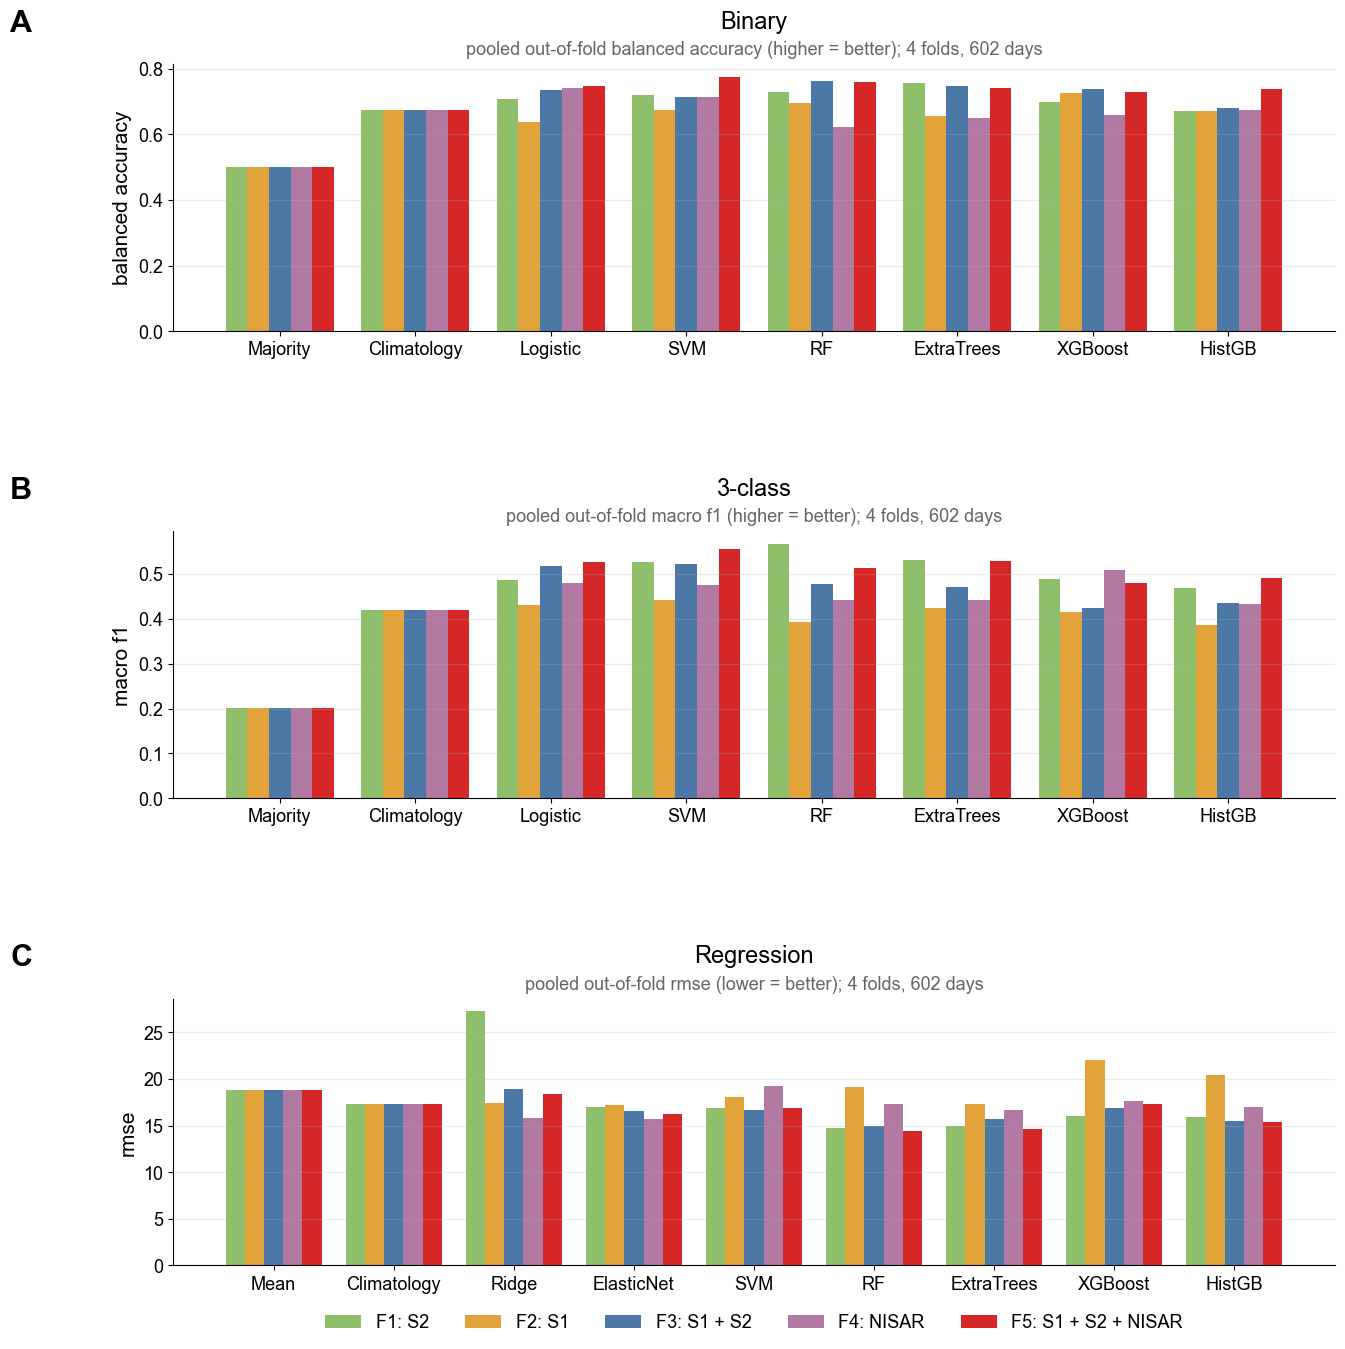

In [10]:
set_colors = dict(zip(FEATURE_SETS, ["#8fbf6a", "#e3a33b", "#4c78a8", "#b279a2", "#d62728"]))
fig, axes = plt.subplots(len(TASKS), 1, figsize=(15, 5.2 * len(TASKS)))
fig.subplots_adjust(hspace=0.75)
for k, (ax, (task, metric)) in enumerate(zip(np.atleast_1d(axes), PRIMARY_METRIC.items())):
    t = pooled[pooled.task == task].pivot(index="model", columns="set", values=metric).loc[list(make_models(task))]
    x = np.arange(len(t)); w = 0.8 / len(FEATURE_SETS)
    for i, s in enumerate(FEATURE_SETS):
        ax.bar(x + (i - (len(FEATURE_SETS) - 1) / 2) * w, t[s], w, label=f"{s}: {' + '.join(FEATURE_SETS[s])}",
               color=set_colors[s])
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_ylabel(metric.replace("_", " "))
    ax.set_title({"binary": "Binary", "3class": "3-class", "regression": "Regression"}[task], pad=26)
    subtitle(ax, f"pooled out-of-fold {metric.replace('_', ' ')}"
                 + (" (lower = better)" if metric in LOWER_IS_BETTER else " (higher = better)")
                 + f"; {len(FOLDS)} folds, {len(df)} days")
    ax.grid(axis="y", alpha=0.25)
    panel_letter(ax, "ABCDEFG"[k])
np.atleast_1d(axes)[-1].legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "primary_metric_by_model.png", dpi=150, bbox_inches="tight")
plt.show()

### Figure: mean ± SD of the fold scores by model and feature set

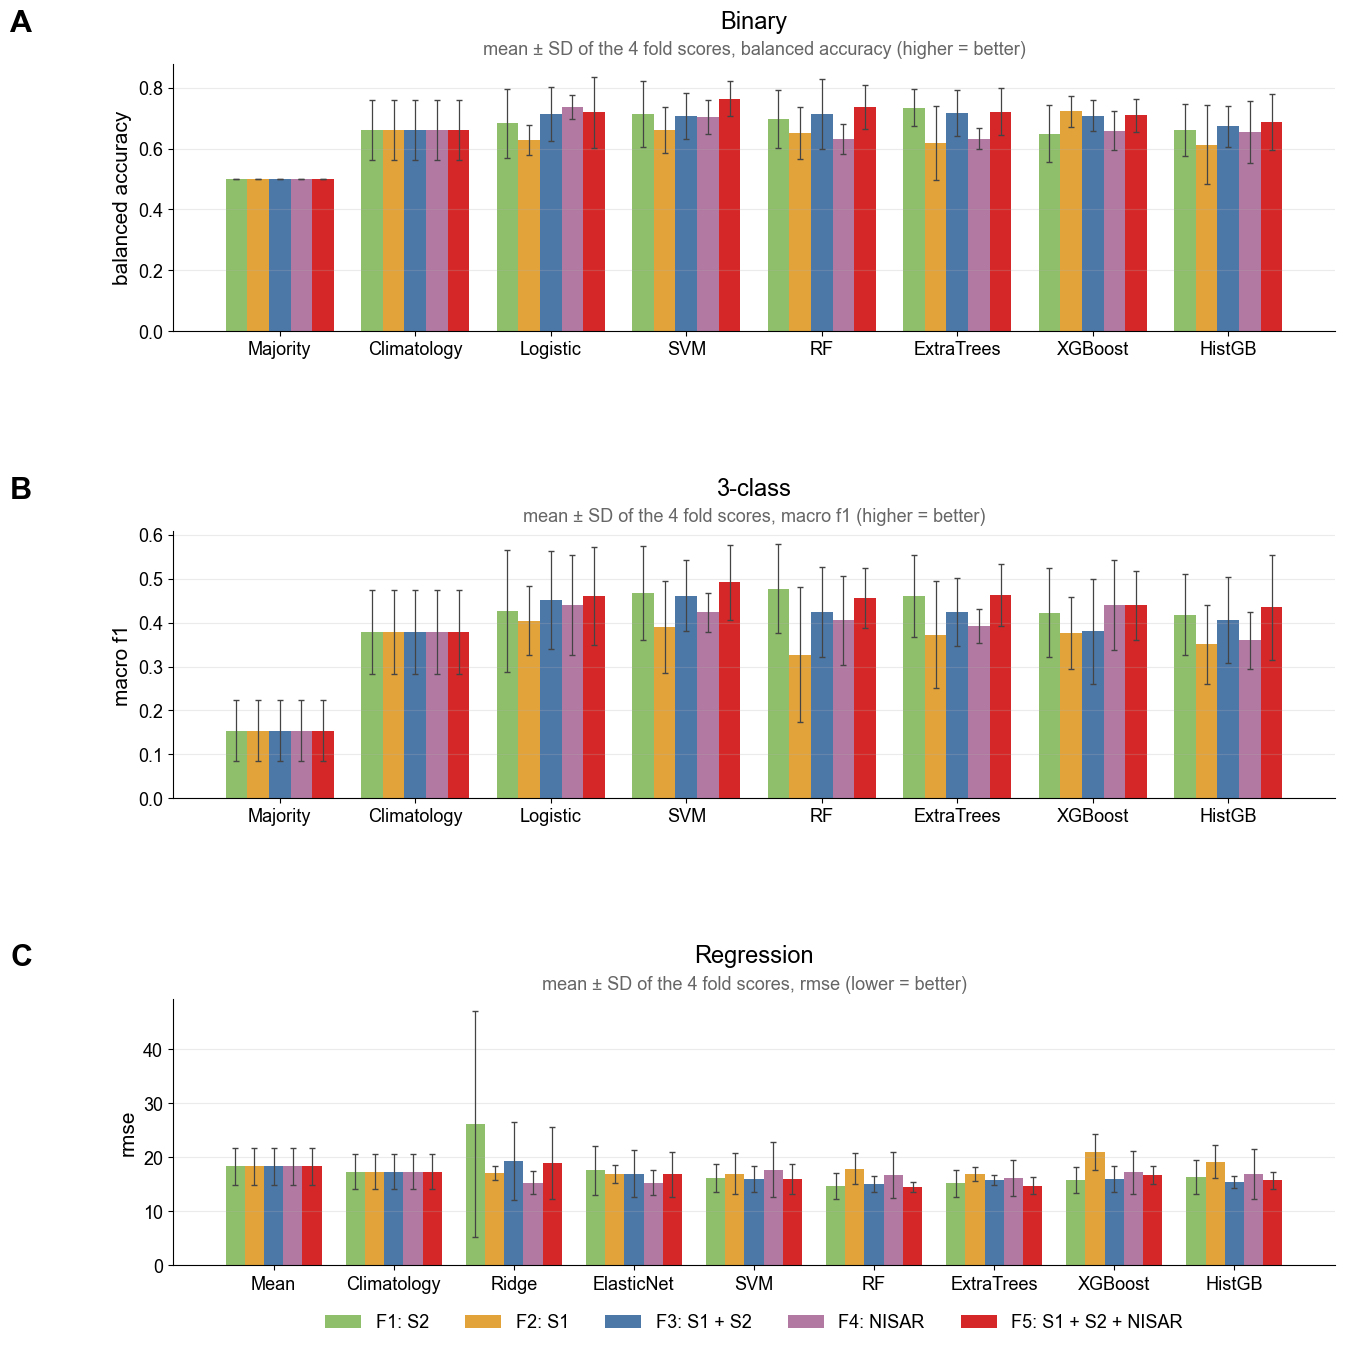

In [11]:
set_colors = dict(zip(FEATURE_SETS, ["#8fbf6a", "#e3a33b", "#4c78a8", "#b279a2", "#d62728"]))
fig, axes = plt.subplots(len(TASKS), 1, figsize=(15, 5.2 * len(TASKS)))
fig.subplots_adjust(hspace=0.75)
for k, (ax, (task, metric)) in enumerate(zip(np.atleast_1d(axes), PRIMARY_METRIC.items())):
    t = fold_stats[fold_stats.task == task]
    mean = t.pivot(index="model", columns="set", values=f"{metric}_mean").loc[list(make_models(task))]
    sd = t.pivot(index="model", columns="set", values=f"{metric}_std").loc[list(make_models(task))]
    x = np.arange(len(mean)); w = 0.8 / len(FEATURE_SETS)
    for i, s in enumerate(FEATURE_SETS):
        ax.bar(x + (i - (len(FEATURE_SETS) - 1) / 2) * w, mean[s], w, yerr=sd[s], capsize=2,
               error_kw=dict(lw=0.9, ecolor="#444444"), label=f"{s}: {' + '.join(FEATURE_SETS[s])}",
               color=set_colors[s])
    ax.set_xticks(x); ax.set_xticklabels(mean.index); ax.set_ylabel(metric.replace("_", " "))
    ax.set_title({"binary": "Binary", "3class": "3-class", "regression": "Regression"}[task], pad=26)
    subtitle(ax, f"mean ± SD of the {len(FOLDS)} fold scores, {metric.replace('_', ' ')}"
                 + (" (lower = better)" if metric in LOWER_IS_BETTER else " (higher = better)"))
    ax.grid(axis="y", alpha=0.25)
    panel_letter(ax, "ABCDEFG"[k])
np.atleast_1d(axes)[-1].legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "fold_mean_sd_by_model.png", dpi=150, bbox_inches="tight")
plt.show()

### Figure: observed vs out-of-fold predicted water level (primary model, F3 vs F5)

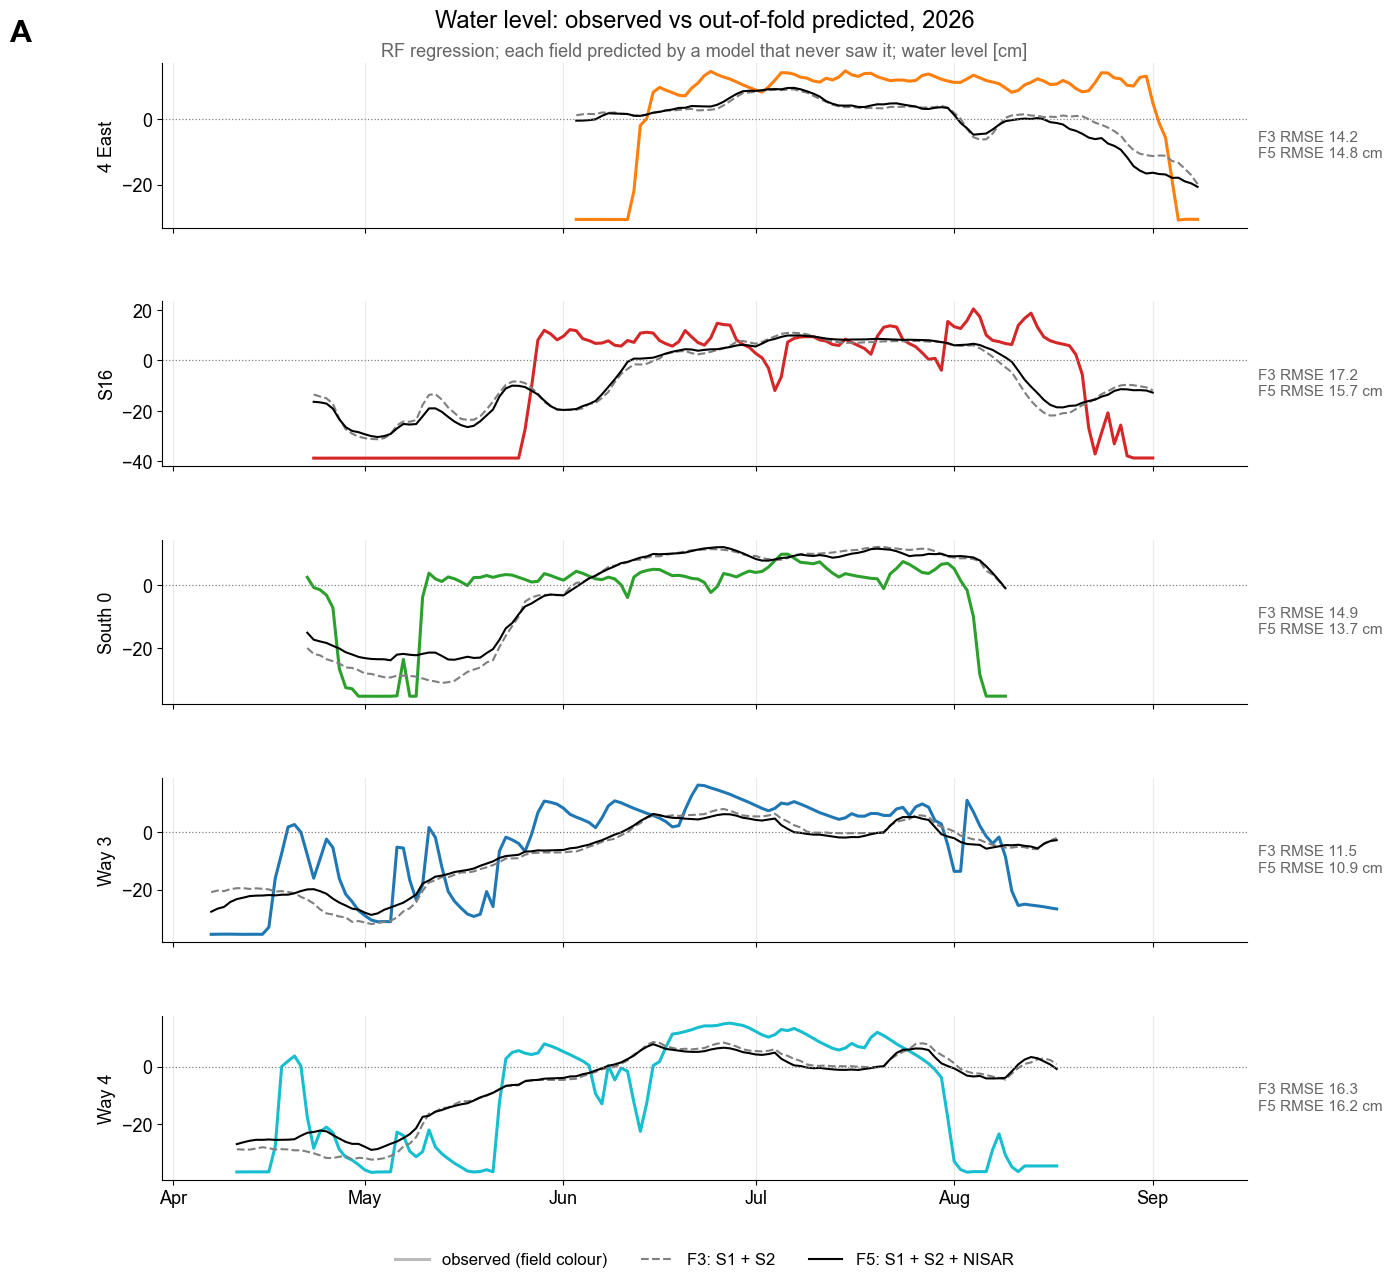

In [12]:
units_list = sorted(df.unit.unique())
r = oof[(oof.task == "regression") & (oof.model == PRIMARY_MODEL)]
fig, axes = plt.subplots(len(units_list), 1, figsize=(14, 2.9 * len(units_list)), sharex=True)
fig.subplots_adjust(hspace=0.45)
set_style = {TEST_SETS[1]: ("#7f7f7f", "--"), TEST_SETS[0]: ("#000000", "-")}   # predictions: neutral, so field colours stay distinct
for k, (ax, gid) in enumerate(zip(axes, units_list)):
    m = (df.unit == gid).values
    fld = df.field[m].iloc[0]
    ax.plot(df.date[m], df.water_cm[m], color=FIELD_COLORS.get(fld, "k"), lw=2.2, label="observed")
    txt = []
    for s, (c, ls) in set_style.items():
        rr = r[r.set == s].set_index("row").loc[np.where(m)[0]]
        ax.plot(df.date[m], rr.pred.values, color=c, lw=1.5, ls=ls, label=f"{s}: {' + '.join(FEATURE_SETS[s])}")
        txt.append(f"{s} RMSE {np.sqrt(np.mean((rr.pred.values - rr.y.values) ** 2)):.1f}")
    ax.axhline(0, color="grey", lw=0.9, ls=":")
    ax.set_ylabel(gid if gid == fld else f"{gid}\n({fld})", fontsize=13)
    ax.text(1.01, 0.5, "\n".join(txt) + " cm", transform=ax.transAxes, va="center", fontsize=11, color="#666666")
    ax.grid(axis="x", alpha=0.25)
axes[0].set_title("Water level: observed vs out-of-fold predicted, 2026", pad=26)
subtitle(axes[0], f"{PRIMARY_MODEL} regression; each field predicted by a model that never saw it; water level [cm]")
from matplotlib.lines import Line2D
axes[-1].legend(handles=[Line2D([], [], color="#bbbbbb", lw=2.2, label="observed (field colour)")] +
                        [Line2D([], [], color=c, ls=ls, lw=1.5, label=f"{s}: {' + '.join(FEATURE_SETS[s])}")
                         for s, (c, ls) in set_style.items()],
                ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.35), fontsize=12)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
panel_letter(axes[0], "A")
fig.savefig(OUT_DIR / "oof_water_level_primary.png", dpi=150, bbox_inches="tight")
plt.show()

### Binary: confusion matrices and the final drydown (F1 vs F3 vs F5)

Per field, out-of-fold predictions of `CM_MODEL` (the field was held out when its predictions were made).
**Final drydown** = the days after the last day with water ≥ 0 cm, i.e. the end-of-season drainage before harvest.
The strips show the observed label and each feature set's predicted label, day by day.

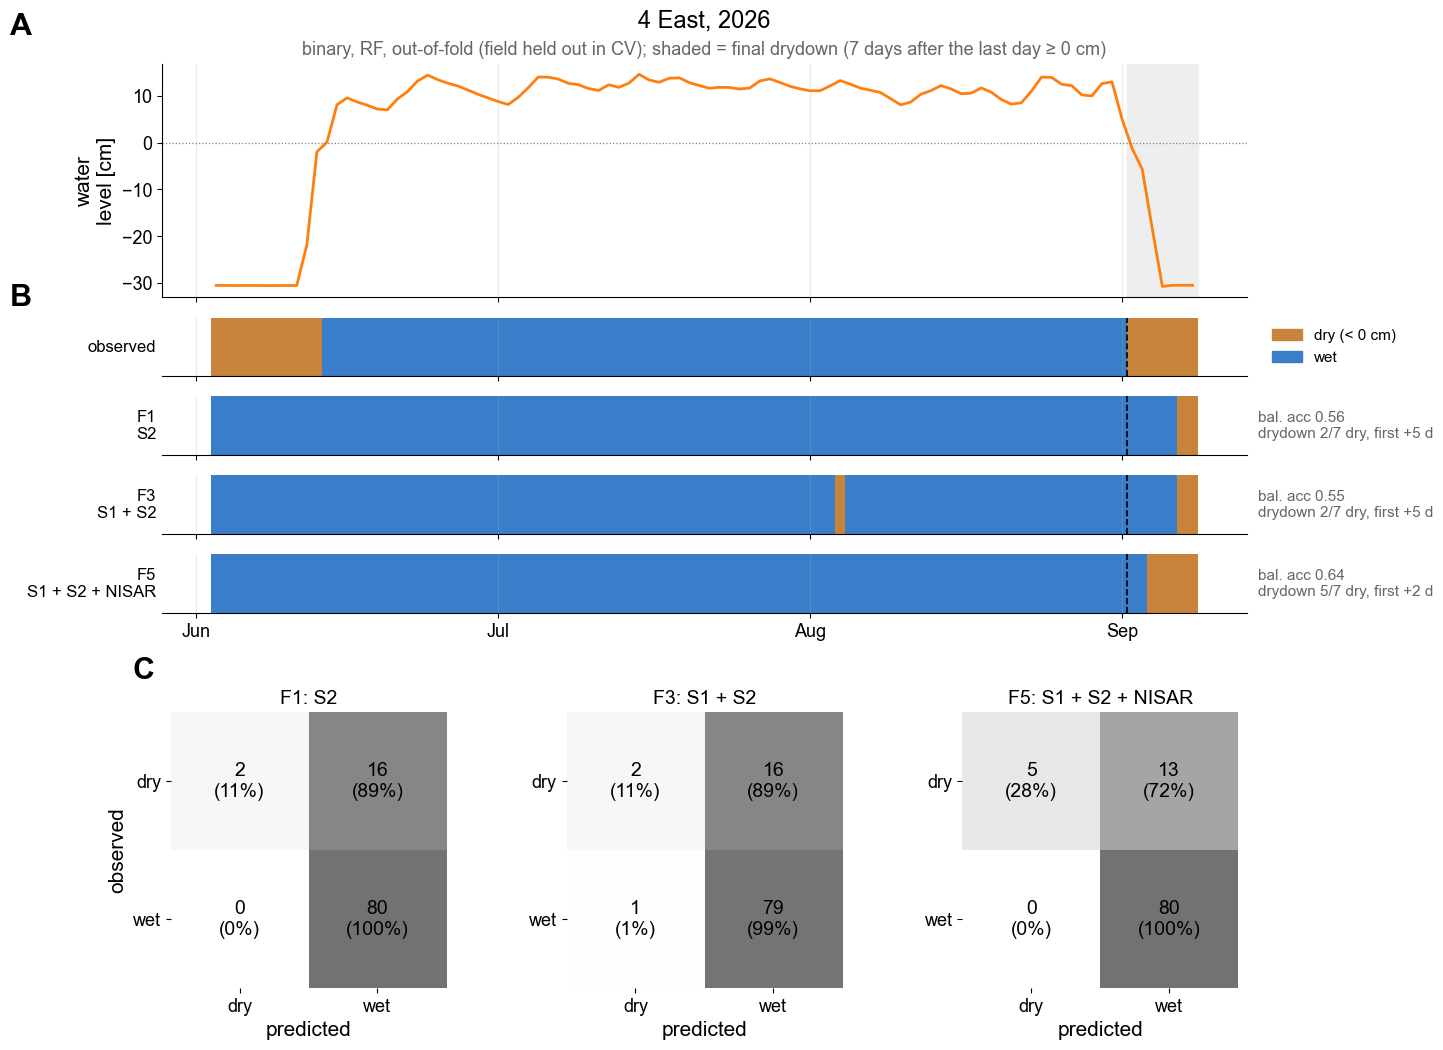

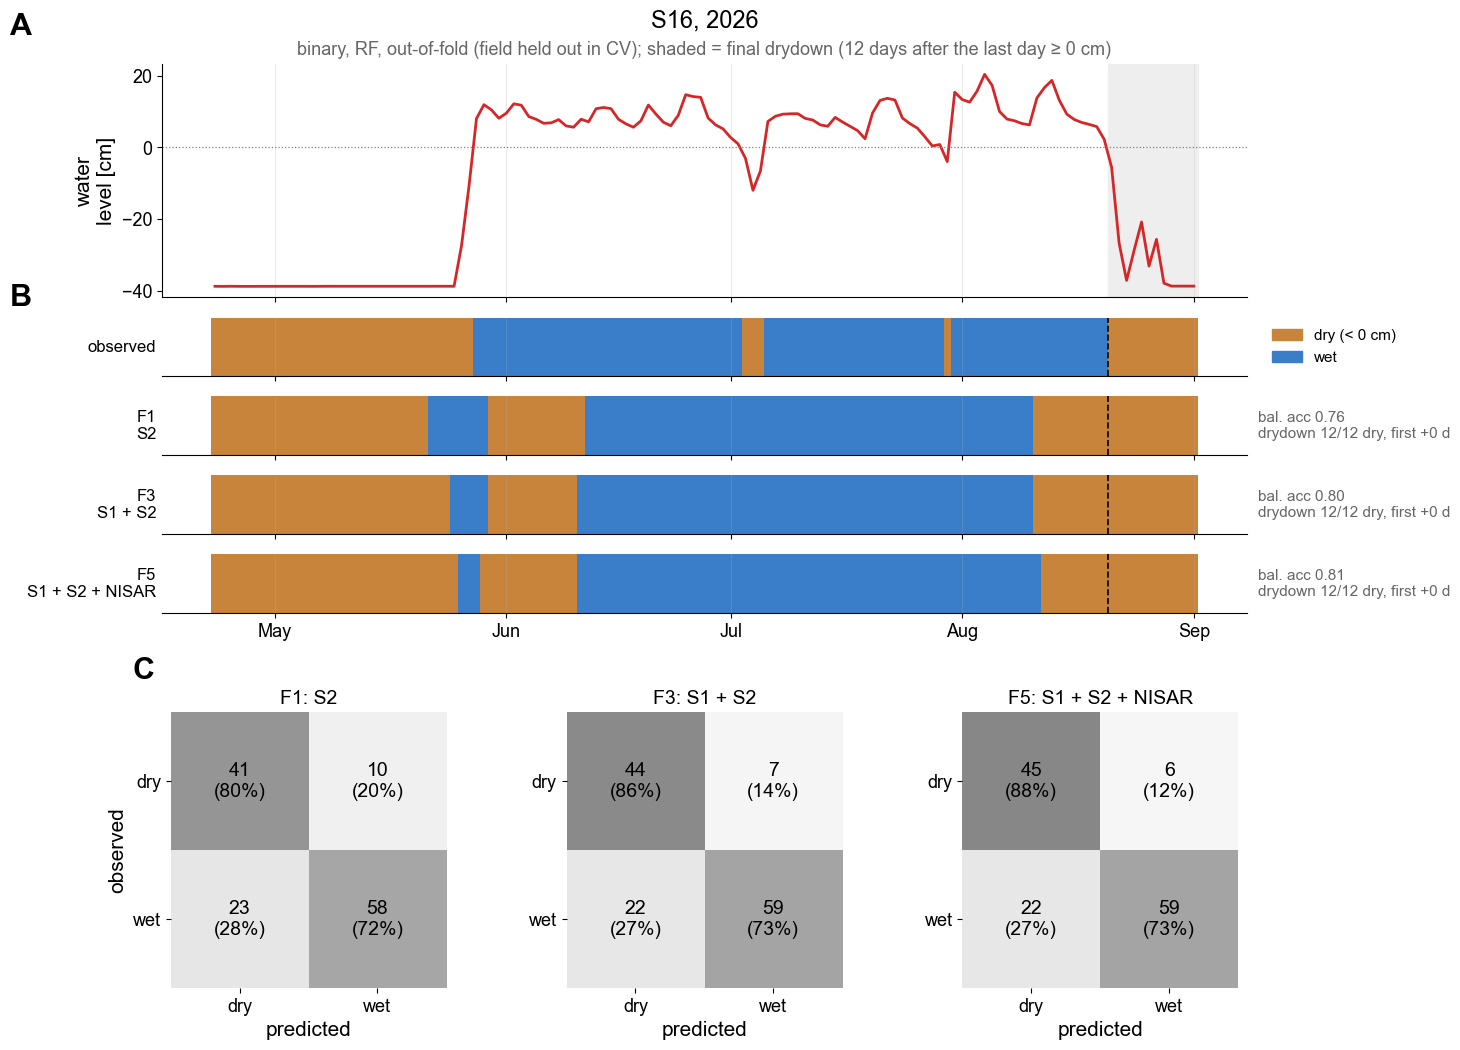

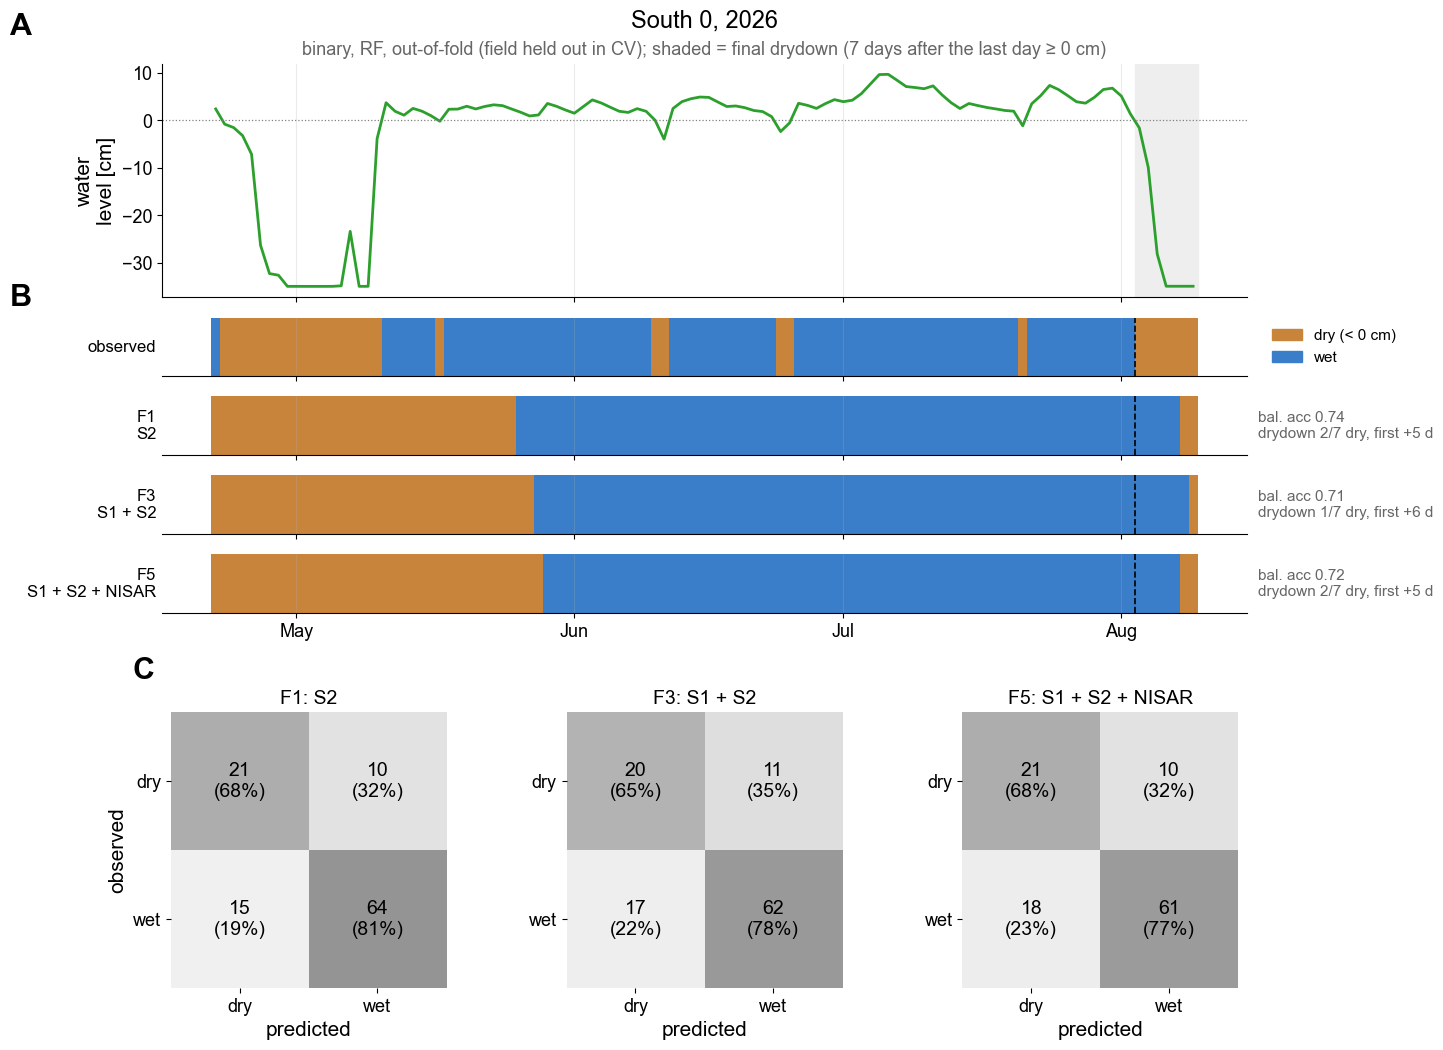

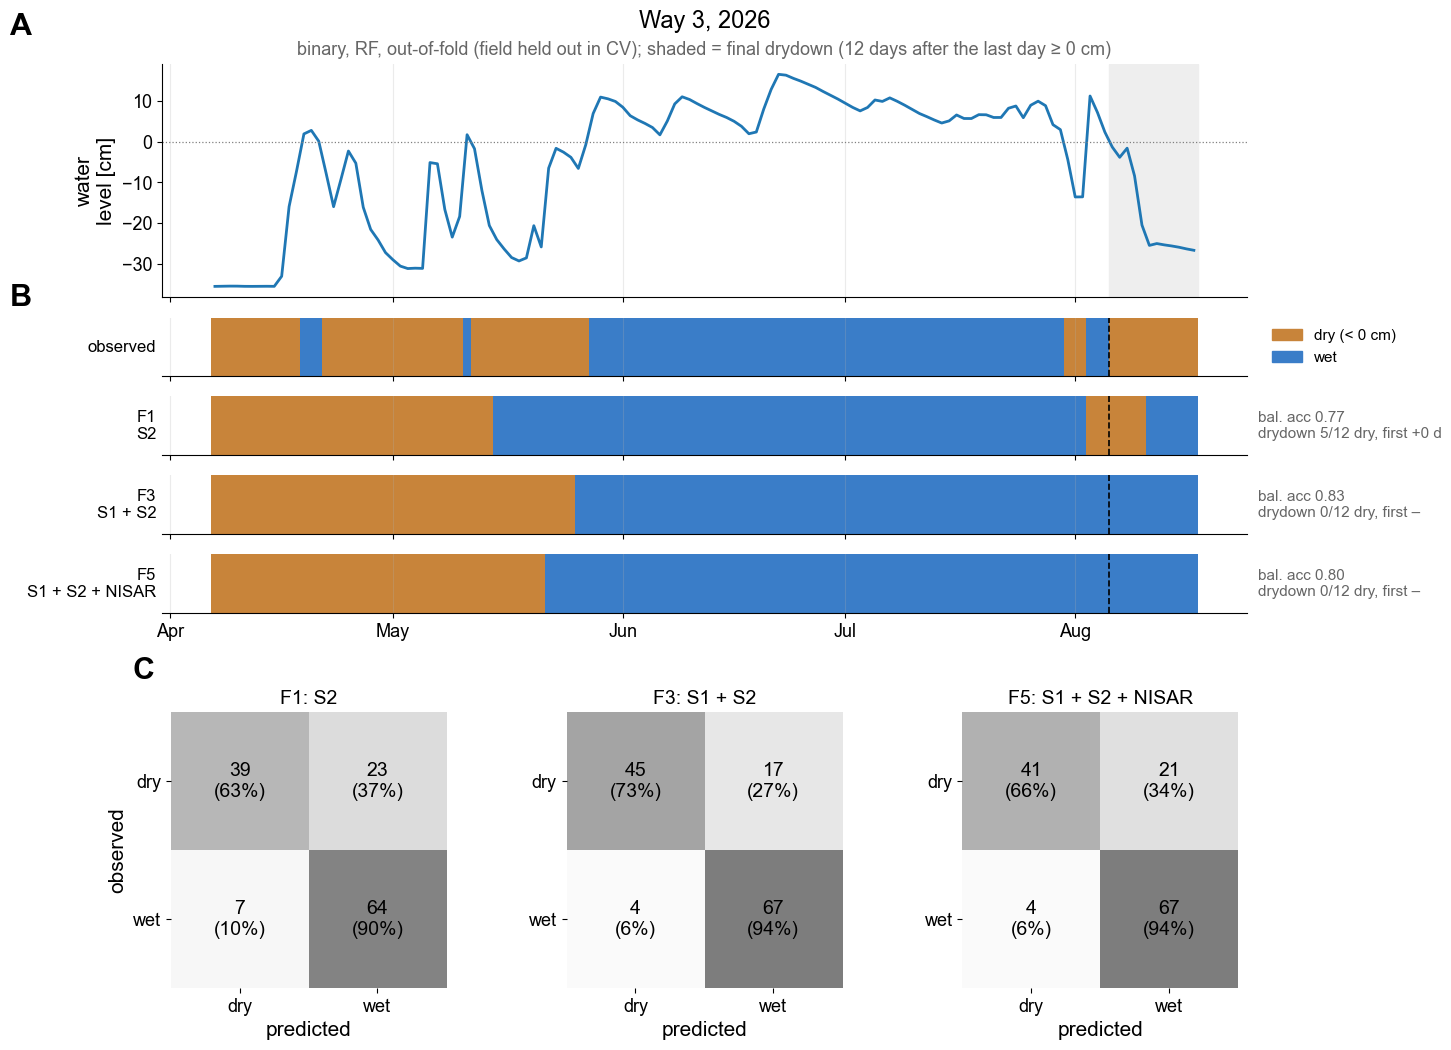

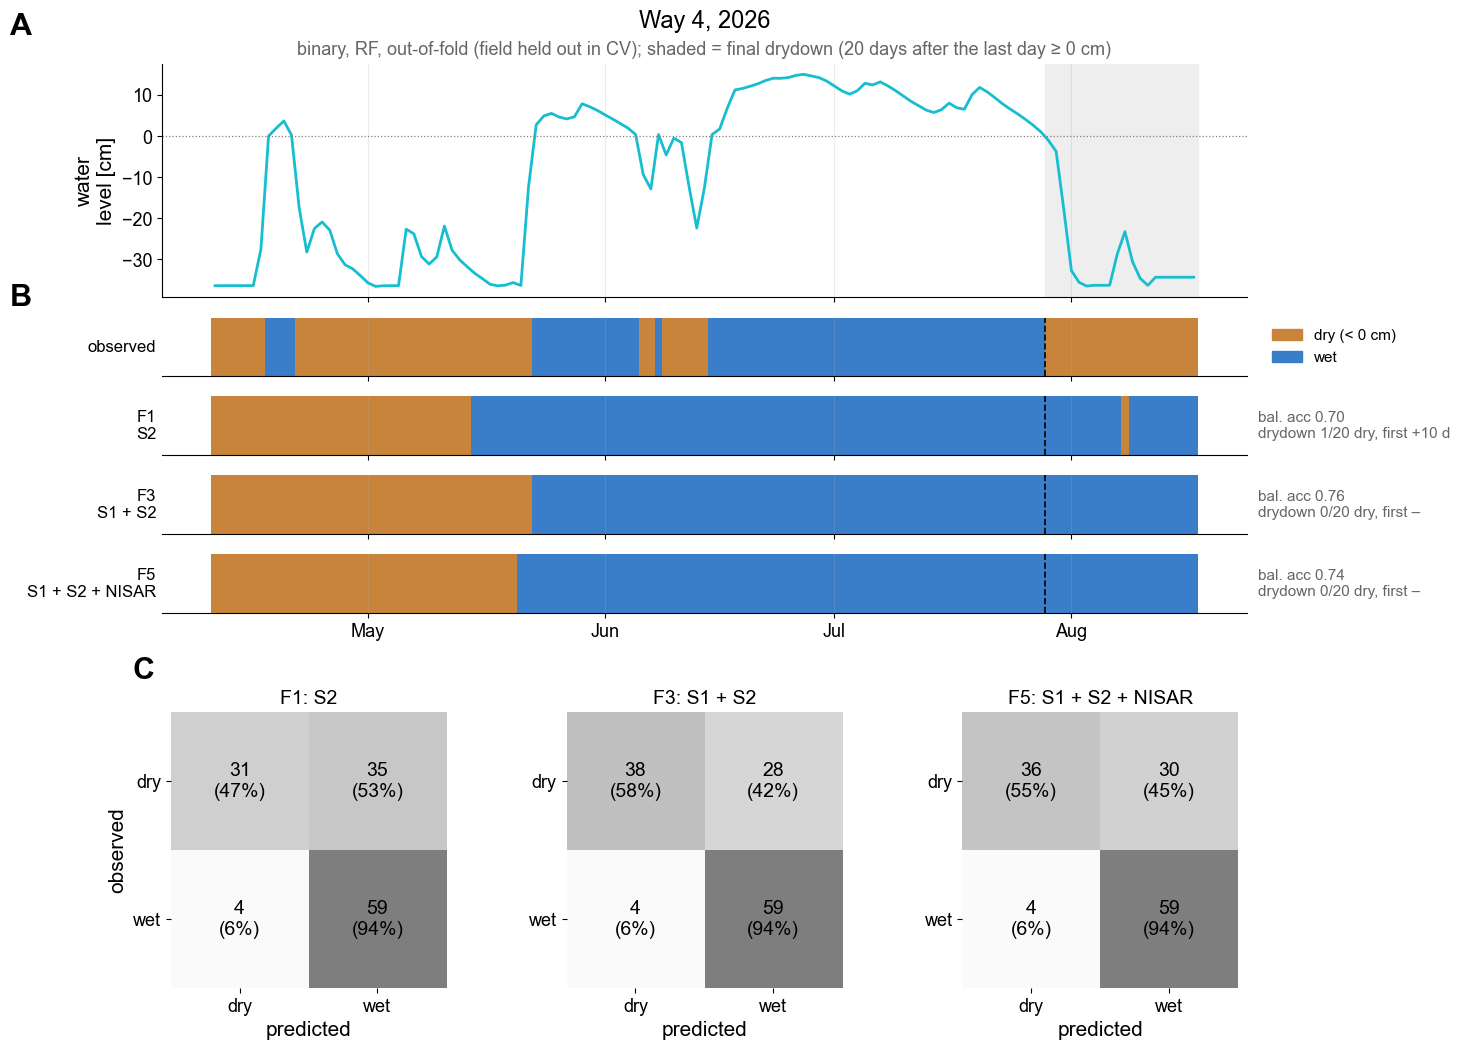

final drydown = days after the last day with water >= 0 cm
  field set  balanced_accuracy  dry_days_all  dry_predicted_dry_all  final_dry_days  final_dry_predicted_dry  final_dry_share  days_to_first_dry_pred
 4 East  F1              0.556            18                      2               7                        2            0.286                     5.0
 4 East  F3              0.549            18                      2               7                        2            0.286                     5.0
 4 East  F5              0.639            18                      5               7                        5            0.714                     2.0
    S16  F1              0.760            51                     41              12                       12            1.000                     0.0
    S16  F3              0.796            51                     44              12                       12            1.000                     0.0
    S16  F5              0.805           

In [13]:
# ---- settings for this section ----
CM_MODEL  = PRIMARY_MODEL            # model to show
CM_SETS   = ["F1", "F3", "F5"]       # feature sets to compare
CM_FIELDS = None                     # None = every field, or e.g. ["S16"]
DRY_COLOR, WET_COLOR = "#c8843a", "#3a7dc8"

b = oof[(oof.task == "binary") & (oof.model == CM_MODEL) & (oof.set.isin(CM_SETS))]
b = b.merge(df[["field", "date", "water_cm"]], left_on="row", right_index=True)

# Final drydown = days after the LAST day with water >= DRY_2C (end-of-season drainage before harvest).
last_wet = df[df.water_cm >= DRY_2C].groupby("field").date.max()
b["final_dry"] = b.date > b.field.map(last_wet)


def drydown_stats(r):
    fd = r[r.final_dry]
    n_ok = int((fd.pred == 0).sum())
    return dict(final_dry_days=len(fd), final_dry_predicted_dry=n_ok,
                final_dry_share=n_ok / len(fd) if len(fd) else np.nan,
                # days from the first final-drydown day to the first day predicted dry in it
                days_to_first_dry_pred=(fd[fd.pred == 0].date.min() - fd.date.min()).days if n_ok else np.nan)


def binary_field_figure(field):
    bf = b[b.field == field]
    obs = bf[bf.set == CM_SETS[0]].sort_values("date")
    dd = obs[obs.final_dry]
    rows = [("observed", obs.y.values, None)] + [
        (s, bf[bf.set == s].sort_values("date").pred.values, bf[bf.set == s]) for s in CM_SETS]

    fig = plt.figure(figsize=(14, 3.2 + 0.9 * len(rows) + 5.2))
    ratios = [2.2] + [0.55] * len(rows) + [0.55, 2.6]                 # A, B strips, spacer, C
    gs = fig.add_gridspec(len(ratios), 1, height_ratios=ratios, hspace=0.18)
    axes = [fig.add_subplot(gs[0])]
    for i in range(len(rows)):
        axes.append(fig.add_subplot(gs[1 + i], sharex=axes[0]))

    # ---- A: water level, final drydown shaded --------------------------------
    ax = axes[0]
    ax.plot(obs.date, obs.water_cm, lw=2, color=FIELD_COLORS.get(field, "k"))
    ax.axhline(DRY_2C, color="grey", lw=0.9, ls=":")
    ax.set_ylabel("water\nlevel [cm]")
    ax.set_title(f"{field}, 2026", pad=26)
    subtitle(ax, f"binary, {CM_MODEL}, out-of-fold (field held out in CV); "
                 f"shaded = final drydown ({len(dd)} days after the last day ≥ {DRY_2C} cm)")
    panel_letter(ax, "A")

    # ---- B: one strip per label series ---------------------------------------
    for ax, (lab, vals, r) in zip(axes[1:], rows):
        ax.bar(obs.date, 1, width=1.0, color=np.where(vals == 0, DRY_COLOR, WET_COLOR), align="center")
        ax.set_ylim(0, 1); ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        ax.set_ylabel(lab if lab == "observed" else f"{lab}\n{' + '.join(FEATURE_SETS[lab])}",
                      fontsize=12, rotation=0, ha="right", va="center")
        if r is not None:
            st = drydown_stats(r)
            ba = balanced_accuracy_score(r.y, r.pred) if r.y.nunique() == 2 else np.nan
            first = "–" if np.isnan(st["days_to_first_dry_pred"]) else f"+{st['days_to_first_dry_pred']:.0f} d"
            ax.text(1.01, 0.5, f"bal. acc {ba:.2f}\ndrydown {st['final_dry_predicted_dry']}/{st['final_dry_days']}"
                               f" dry, first {first}", transform=ax.transAxes, va="center",
                    fontsize=11, color="#666666")
    panel_letter(axes[1], "B")
    axes[1].legend(handles=[Patch(color=DRY_COLOR, label=f"dry (< {DRY_2C} cm)"),
                            Patch(color=WET_COLOR, label="wet")],
                   ncol=1, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=11)
    if len(dd):
        start = dd.date.min() - pd.Timedelta(hours=12)
        axes[0].axvspan(start, dd.date.max() + pd.Timedelta(hours=12), color="#eeeeee", zorder=0)
        for ax in axes[1:]:                                # strips are filled: mark drydown start instead
            ax.axvline(start, color="k", lw=1.2, ls="--")
    for ax in axes:
        ax.grid(axis="x", alpha=0.25)
    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))

    # ---- C: confusion matrices -----------------------------------------------
    sub = gs[-1].subgridspec(1, len(CM_SETS), wspace=0.35)
    for j, s in enumerate(CM_SETS):
        r = bf[bf.set == s]
        cm = confusion_matrix(r.y, r.pred, labels=[0, 1])
        pct = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax = fig.add_subplot(sub[0, j])
        ax.imshow(pct, cmap="Greys", vmin=0, vmax=1.6)
        for (i, k), v in np.ndenumerate(cm):
            ax.text(k, i, f"{v}\n({pct[i, k]:.0%})", ha="center", va="center", fontsize=14)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["dry", "wet"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["dry", "wet"])
        ax.set_xlabel("predicted")
        if j == 0:
            ax.set_ylabel("observed")
        ax.set_title(f"{s}: {' + '.join(FEATURE_SETS[s])}", fontsize=14)
        for sp in ax.spines.values():
            sp.set_visible(False)
        if j == 0:
            panel_letter(ax, "C")
    return fig


summary = []
for field in (CM_FIELDS or sorted(df.field.unique())):
    fig = binary_field_figure(field)
    fig.savefig(OUT_DIR / f"binary_cm_{field.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()
    for s in CM_SETS:
        r = b[(b.field == field) & (b.set == s)]
        summary.append(dict(field=field, set=s,
                            balanced_accuracy=balanced_accuracy_score(r.y, r.pred) if r.y.nunique() == 2 else np.nan,
                            dry_days_all=int((r.y == 0).sum()), dry_predicted_dry_all=int(((r.y == 0) & (r.pred == 0)).sum()),
                            **drydown_stats(r)))

cm_summary = pd.DataFrame(summary)
print("final drydown = days after the last day with water >= 0 cm")
print(cm_summary.round(3).to_string(index=False))
cm_summary.to_csv(OUT_DIR / "binary_final_drydown_summary.csv", index=False)

## 6. Hold-out test (only if `HOLDOUT_FIELDS` is set)

Each model is refit once on **all** development rows and scored once on the locked hold-out field. No choices are made from these numbers.
Note: with few days of a class in the hold-out field, its macro-F1 is dominated by those days (e.g. 4 East has 1 middle-class day).

In [14]:
ho_rows, ho_pred_rows = [], []
if RUN_HOLDOUT:
    for task, target in TASKS.items():
        cast = float if task == "regression" else int
        y_dev, y_te = df[target].values.astype(cast), df_test[target].values.astype(cast)
        for set_name in FEATURE_SETS:
            cols = feature_cols(set_name)
            for name, (est, how) in make_models(task).items():
                m = clone(est).fit(model_input(df[cols], how), y_dev)
                X_te = model_input(df_test[cols], how, frame=df_test)
                pred = m.predict(X_te)
                p1 = None
                if task == "binary" and hasattr(m, "predict_proba"):
                    cls = list(m.classes_)
                    p1 = m.predict_proba(X_te)[:, cls.index(1)] if 1 in cls else np.zeros(len(y_te))
                ho_rows.append(dict(task=task, set=set_name, model=name, n=len(y_te), **metrics(task, y_te, pred, p1)))
                ho_pred_rows.append(pd.DataFrame(dict(task=task, set=set_name, model=name, unit=df_test.unit,
                                                      date=df_test.date, y=y_te, pred=pred,
                                                      proba1=p1 if p1 is not None else np.nan)))
    holdout = pd.DataFrame(ho_rows); holdout_pred = pd.concat(ho_pred_rows, ignore_index=True)
    print(f"hold-out field(s): {HOLDOUT_FIELDS}, n = {len(df_test)} days")
    for task, metric in PRIMARY_METRIC.items():
        t = holdout[holdout.task == task].pivot(index="model", columns="set", values=metric).loc[list(make_models(task))]
        print(f"\n{task} — {metric} (hold-out)")
        print(t.round(3).to_string())

### Figure: hold-out water level, observed vs predicted (primary model, F3 vs F5)

In [15]:
if RUN_HOLDOUT:
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(df_test.date, df_test.water_cm, color="k", lw=2, label="observed")
    r = holdout_pred[(holdout_pred.task == "regression") & (holdout_pred.model == PRIMARY_MODEL)]
    for s, c in zip(TEST_SETS, ["#d62728", "#4c78a8"]):
        rr = r[r.set == s]
        rmse = holdout[(holdout.task == "regression") & (holdout.model == PRIMARY_MODEL) & (holdout.set == s)].rmse.iloc[0]
        ax.plot(rr.date, rr.pred, color=c, lw=1.5, label=f"{s} prediction (RMSE {rmse:.1f} cm)")
    ax.axhline(0, color="grey", lw=0.8, ls="--"); ax.set_ylabel("water level (cm)")
    ax.set_title(f"Hold-out: {', '.join(HOLDOUT_FIELDS)} — {PRIMARY_MODEL} regression")
    ax.legend(loc="lower left", frameon=False)
    ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.tight_layout()
    fig.savefig(OUT_DIR / "holdout_water_level_primary.png", dpi=150, bbox_inches="tight")
    plt.show()

## 7. Hypothesis test: F5 vs F3 (primary model)

Δ = metric(F5) − metric(F3), signed so that **Δ > 0 means F5 is better** (for RMSE: Δ = RMSE(F3) − RMSE(F5)).

* **Permutation test.** Each field's NISAR feature series is replaced by another field's series on the same dates (all n! permutations of the n development fields, identity included; 4 fields → 24), and the full F5 cross-validation is refit. p = share of permutations with Δ ≥ observed Δ. Smallest possible p = 1/n!. Way 3 and Way 4 are adjacent, so swaps between them change the NISAR series less than other swaps.
* **Bootstrap CI.** On the fixed out-of-fold predictions: resample the development fields with replacement, then within each sampled field resample its `BLOCK_DAYS`-day blocks (per unit) with replacement. 95 % percentile CI of Δ.

In [16]:
def delta(task, y, pred_with, pred_without, p_with=None, p_without=None):
    metric = PRIMARY_METRIC[task]
    a = metrics(task, y, pred_with, p_with)[metric]; b = metrics(task, y, pred_without, p_without)[metric]
    return (b - a) if metric in LOWER_IS_BETTER else (a - b)

nisar_cols = [c for c in feature_cols(TEST_SETS[0]) if c.startswith(SENSORS["NISAR"])]
fields = sorted(df.field.unique())

def permuted_X(perm):
    # F5 features with each field's NISAR columns taken from field perm[field] on the same date.
    X = df[feature_cols(TEST_SETS[0])].copy()
    donor = df.field.map(perm)
    X[nisar_cols] = fields_tbl.reindex(pd.MultiIndex.from_arrays([donor, df.date]))[nisar_cols].values
    return X

def all_perms():
    perms = [dict(zip(fields, p)) for p in itertools.permutations(fields)]
    if N_PERM == "all":
        return perms
    rng = np.random.default_rng(SEED)
    ident = dict(zip(fields, fields))
    return [ident] + [perms[i] for i in rng.choice(len(perms), size=int(N_PERM), replace=False)]

# Bootstrap units: field -> list of row-index arrays (unit x block)
df["_block"] = df.groupby("unit").date.transform(lambda d: ((d - d.min()).dt.days // BLOCK_DAYS))
units = {f: [g.index.values for _, g in df[df.field == f].groupby(["unit", "_block"])] for f in fields}

def boot_ci(task, y, pw, pwo, p1w, p1wo):
    rng = np.random.default_rng(SEED); out = []
    for _ in range(N_BOOT):
        idx = np.concatenate([u for f in rng.choice(fields, len(fields), replace=True)
                              for u in (lambda us: [us[i] for i in rng.integers(0, len(us), len(us))])(units[f])])
        yy = y[idx]
        if task != "regression" and len(np.unique(yy)) < 2:
            continue
        out.append(delta(task, yy, pw[idx], pwo[idx],
                         None if p1w is None else p1w[idx], None if p1wo is None else p1wo[idx]))
    return np.percentile(out, [2.5, 97.5]), len(out)

In [17]:
sig_rows, null_rows = [], []
if RUN_SIGNIFICANCE:
    perms = all_perms()
    est_by_task = {t: make_models(t)[PRIMARY_MODEL][0] for t in TASKS}
    for task, target in TASKS.items():
        y = df[target].values.astype(float if task == "regression" else int)
        o = oof[(oof.task == task) & (oof.model == PRIMARY_MODEL)]
        w, wo = (o[o.set == s].sort_values("row") for s in TEST_SETS)
        p1w = w.proba1.values if task == "binary" else None
        p1wo = wo.proba1.values if task == "binary" else None
        d_obs = delta(task, y, w.pred.values, wo.pred.values, p1w, p1wo)

        t0 = time.time(); d_null = []
        for i, perm in enumerate(perms):
            pred, p1 = run_cv(est_by_task[task], permuted_X(perm), y, task)
            d = delta(task, y, pred, wo.pred.values, p1, p1wo)
            d_null.append(d)
            null_rows.append(dict(task=task, perm=i, identity=all(k == v for k, v in perm.items()),
                                  mapping=str(perm), delta=d))
            if (i + 1) % 20 == 0:
                print(f"  {task}: {i + 1}/{len(perms)} permutations ({time.time() - t0:.0f} s)")
        d_null = np.array(d_null)
        ci, n_ok = boot_ci(task, y, w.pred.values, wo.pred.values, p1w, p1wo)
        sig_rows.append(dict(task=task, metric=PRIMARY_METRIC[task], model=PRIMARY_MODEL,
                             F5=metrics(task, y, w.pred.values, p1w)[PRIMARY_METRIC[task]],
                             F3=metrics(task, y, wo.pred.values, p1wo)[PRIMARY_METRIC[task]],
                             delta=d_obs, perm_p=np.mean(d_null >= d_obs - 1e-12), n_perm=len(d_null),
                             boot_ci_low=ci[0], boot_ci_high=ci[1], n_boot=n_ok))
    sig = pd.DataFrame(sig_rows); perm_null = pd.DataFrame(null_rows)
    print(); print(sig.round(4).to_string(index=False))

### Figure: permutation null distributions

In [18]:
if RUN_SIGNIFICANCE:
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6 * len(TASKS), 5))
    for ax, task in zip(np.atleast_1d(axes), TASKS):
        d = perm_null[perm_null.task == task]; s = sig[sig.task == task].iloc[0]
        ax.hist(d.delta, bins=25, color="#bbbbbb", edgecolor="white")
        ax.axvline(s.delta, color="#d62728", lw=2.5, label=f"observed Δ = {s.delta:.3f}")
        ax.set_title(f"{task}\npermutation p = {s.perm_p:.3f} (n = {int(s.n_perm)})")
        ax.set_xlabel(f"Δ {PRIMARY_METRIC[task]} (F5 better →)"); ax.set_ylabel("permutations")
        ax.legend(loc="upper left", fontsize=12, frameon=False)
        panel_letter(ax, "ABC"[list(TASKS).index(task)])
    fig.tight_layout()
    fig.savefig(OUT_DIR / "permutation_null.png", dpi=150, bbox_inches="tight")
    plt.show()

## 8. Save

In [19]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
pooled.to_csv(OUT_DIR / "results_pooled.csv", index=False)
by_fold.to_csv(OUT_DIR / "results_by_fold.csv", index=False)
fold_stats.to_csv(OUT_DIR / "results_fold_mean_sd.csv", index=False)
oof.merge(df[["unit", "field", "group", "date"]], left_on="row", right_index=True) \
   .to_csv(OUT_DIR / "oof_predictions.csv", index=False)
if RUN_HOLDOUT:
    holdout.to_csv(OUT_DIR / "results_holdout.csv", index=False)
    holdout_pred.to_csv(OUT_DIR / "holdout_predictions.csv", index=False)
if RUN_SIGNIFICANCE:
    sig.to_csv(OUT_DIR / "significance_F5_vs_F3.csv", index=False)
    perm_null.to_csv(OUT_DIR / "permutation_null.csv", index=False)
print("saved to", OUT_DIR.relative_to(ROOT), ":", sorted(p.name for p in OUT_DIR.iterdir()))

saved to outputs/model : ['binary_cm_4_East.png', 'binary_cm_S16.png', 'binary_cm_South_0.png', 'binary_cm_Way_3.png', 'binary_cm_Way_4.png', 'binary_final_drydown_summary.csv', 'fold_mean_sd_by_model.png', 'oof_predictions.csv', 'oof_water_level_primary.png', 'primary_metric_by_model.png', 'results_by_fold.csv', 'results_fold_mean_sd.csv', 'results_pooled.csv']
